# Dataset Audit

## 1. Imports y Configuración

In [77]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import json
import random

import pandas as pd
from PIL import Image
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)

## 2. Drive y Rutas

In [18]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/NoteVision')
RAW_DIR = PROJECT_DIR / 'data_raw'
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts'
LOCAL_DIR = Path('/content/primus')

for d in (RAW_DIR, ARTIFACTS_DIR, LOCAL_DIR):
    if d.exists():
        print(f"{d} already mounted")
    else:
        d.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/NoteVision/data_raw already mounted
/content/drive/MyDrive/NoteVision/artifacts already mounted
/content/primus already mounted


## 3. Descarga

In [15]:
PRIMUS_URL = "https://grfia.dlsi.ua.es/primus/packages/primusCalvoRizoAppliedSciences2018.tgz"
ARCHIVE = RAW_DIR / 'primus.tgz'

if not ARCHIVE.exists():
  !wget -O $ARCHIVE $PRIMUS_URL
else:
  print(f"{ARCHIVE} already exists\n")

print('Archive size (GB):', round(ARCHIVE.stat().st_size / 1e9, 2))

/content/drive/MyDrive/NoteVision/data_raw/primus.tgz already exists

Archive size (GB): 0.27


## 4. Extracción

In [22]:
if not any(LOCAL_DIR.iterdir()):
  !tar -xzf $ARCHIVE -C $LOCAL_DIR
else:
  print(f"{LOCAL_DIR} already contains files\n")

print([p.name for p in LOCAL_DIR.iterdir()][:10])

/content/primus already contains files

['package_aa', 'package_ab']


## 5. Inspección de Estructura

In [53]:
PACKAGE_DIRS = [LOCAL_DIR / 'package_aa', LOCAL_DIR / 'package_ab']

paths = {}
dup_ids_across_packages = []
for pkg in PACKAGE_DIRS:
    for d in sorted(pkg.iterdir()):
        if d.is_dir() and not d.name.startswith('._'):
            if d.name in paths:
                dup_ids_across_packages.append(d.name)
            paths[d.name] = d

print('Total samples:', len(paths))
print('IDs repeated across packages:', len(dup_ids_across_packages))

Total samples: 87678
IDs repeated across packages: 0


## 6. Índice

In [54]:
rows = []
for sid, d in paths.items():
  rows.append({
    'id': sid,
    'has_png': (d / f'{sid}.png').exists(),
    'has_agnostic': (d / f'{sid}.agnostic').exists(),
    'has_semantic': (d / f'{sid}.semantic').exists(),
    'has_mei': (d / f'{sid}.mei').exists(),
  })
index_df = pd.DataFrame(rows)
print(index_df.drop(columns='id').sum())
print('Incomplete (missing png or agnostic):',
 (~(index_df.has_png & index_df.has_agnostic)).sum())

has_png         87678
has_agnostic    87678
has_semantic    87678
has_mei         87678
dtype: int64
Incomplete (missing png or agnostic): 0


## 7. Tamaño de imagenes

In [55]:
sample_ids = random.sample(list(index_df.id), k=min(2000, len(index_df)))
img_rows = []
for sid in sample_ids:
    with Image.open(paths[sid] / f'{sid}.png') as im:
        img_rows.append({'id': sid, 'width': im.width, 'height': im.height, 'mode': im.mode})
img_df = pd.DataFrame(img_rows)
print(img_df[['width', 'height']].describe())
print('\n', img_df['mode'].value_counts())

             width       height
count  2000.000000  2000.000000
mean   1322.723500   142.715000
std     342.629788    15.390296
min     308.000000    74.000000
25%    1085.000000   129.000000
50%    1272.000000   143.000000
75%    1484.250000   155.000000
max    2003.000000   209.000000

 mode
P    2000
Name: count, dtype: int64


## 8. Etiquetas y vocabulario

In [56]:
def read_tokens(sid):
    return (paths[sid] / f'{sid}.agnostic').read_text(encoding='utf-8').split()

labels = {sid: read_tokens(sid) for sid in index_df.id}
lengths = pd.Series({sid: len(t) for sid, t in labels.items()})
print(lengths.describe())

vocab = Counter(tok for toks in labels.values() for tok in toks)
print('\nVocabulary size:', len(vocab))
print('Tokens with freq < 5:', sum(1 for c in vocab.values() if c < 5))
print('Most common tokens:', vocab.most_common(15))

count    87678.000000
mean        27.458929
std          6.890075
min          3.000000
25%         23.000000
50%         27.000000
75%         32.000000
max         75.000000
dtype: float64

Vocabulary size: 758
Tokens with freq < 5: 90
Most common tokens: [('barline-L1', 326984), ('rest.quarter-L3', 50860), ('note.quarter-L4', 48980), ('clef.G-L2', 48281), ('rest.eighth-L3', 48214), ('note.quarter-S3', 45586), ('note.quarter-S4', 43242), ('note.quarter-L3', 38348), ('note.quarter-L5', 35504), ('note.eighth-L4', 32414), ('metersign.C-L3', 32244), ('dot-S4', 31336), ('note.eighth-S4', 31214), ('note.quarter-S2', 30115), ('note.eighth-S3', 30049)]


### 8.1. Familias y Subgrupos

In [60]:
# Token families (text before the first '-')
families = Counter(tok.split('-')[0] for tok in vocab.elements())
print('Families:', len(families))
print('Most common:', families.most_common(20))

# Token subgroups (text after the first '-')
subgroups = Counter(tok.split('-')[1] for tok in vocab.elements())
print('\nSubgroups:', len(subgroups))
print('Most common:', subgroups.most_common(20))

# Keys related to position of notes
keys_position = sorted(subgroups.keys())
print('\nKeys related to position of notes:')
print(keys_position[:10])
print(keys_position[11:])


Families: 73
Most common: [('note.quarter', 344660), ('barline', 326984), ('note.eighth', 222497), ('note.beamedRight1', 135838), ('dot', 118656), ('note.half', 109262), ('note.beamedLeft1', 103241), ('note.beamedBoth2', 92354), ('note.beamedLeft2', 89621), ('accidental.sharp', 83682), ('accidental.flat', 74776), ('note.beamedBoth1', 74060), ('note.beamedRight2', 64838), ('rest.quarter', 50860), ('clef.G', 48876), ('rest.eighth', 48214), ('note.sixteenth', 36739), ('clef.C', 33496), ('metersign.C', 32244), ('digit.4', 30987)]

Subgroups: 20
Most common: [('L1', 396312), ('L3', 374683), ('L4', 265894), ('S3', 232929), ('S4', 222815), ('L2', 186130), ('L5', 169494), ('S5', 162438), ('S2', 153919), ('S1', 64710), ('L6', 62241), ('S6', 43246), ('S0', 28134), ('L7', 12194), ('L0', 11565), ('S', 8558), ('S7', 7080), ('L', 3633), ('L8', 1152), ('S8', 417)]

Keys related to position of notes:
['L', 'L0', 'L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'L7', 'L8']
['S0', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6',

## 9. Duplicados

In [62]:
label_str = pd.Series({sid: ' '.join(t) for sid, t in labels.items()})
dup_mask = label_str.duplicated(keep=False)
dup_groups = label_str[dup_mask].groupby(label_str[dup_mask]).apply(list)

print('Distinct label sequences repeated:', len(dup_groups))

print('\nSamples involved:', int(dup_mask.sum()))

# Identical image files
hashes = {sid: hashlib.md5((paths[sid] / f'{sid}.png').read_bytes()).hexdigest()
          for sid in sample_ids}
print('\nDuplicate images in the sample:', len(hashes) - len(set(hashes.values())))

# Source piece = ID prefix before '-' (candidate grouping key for leak-free splits)
source_id = index_df.id.str.split('-').str[0]
print('\nDistinct source pieces:', source_id.nunique())
print(source_id.value_counts().describe())

Distinct label sequences repeated: 3157

Samples involved: 7118

Duplicate images in the sample: 4

Distinct source pieces: 61772
count    61772.000000
mean         1.419381
std          1.456283
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         59.000000
Name: count, dtype: float64


### 9.1.Grupos Anti-Fuga

In [65]:
parent = {}

def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

for sid, src in zip(index_df.id, source_id):
    union(('id', sid), ('src', src))
for sid, seq in label_str.items():
    union(('id', sid), ('seq', seq))

group_of = pd.Series({sid: find(('id', sid)) for sid in index_df.id})
group_sizes = group_of.value_counts()

print('Leak-free groups:', len(group_sizes))
print(group_sizes.describe())

print('\nLargest groups:', group_sizes.head(5).tolist())

print('\nLargest group as % of dataset:', round(100 * group_sizes.iloc[0] / len(index_df), 2))

Leak-free groups: 58577
count    58577.000000
mean         1.496799
std          2.283427
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        194.000000
Name: count, dtype: float64

Largest groups: [194, 123, 117, 115, 99]

Largest group as % of dataset: 0.22


### 9.2. Tokens Anómalos

In [68]:
no_pos = [t for t in vocab if t.endswith('-L') or t.endswith('-S')]
no_dash = [t for t in vocab if '-' not in t]

print('Tokens ending in -L/-S without number:', len(no_pos))
print(sorted(no_pos, key=vocab.get, reverse=True)[:10])

print('\nTokens without "-":', no_dash[:10])
print('Rarest tokens:', sorted(vocab.items(), key=lambda kv: kv[1])[:10])

Tokens ending in -L/-S without number: 0
[]

Tokens without "-": []
Rarest tokens: [('note.beamedLeft0-S-2', 1), ('note.beamedRight0-L0', 1), ('accidental.natural-S-3', 1), ('note.double_whole-S7', 1), ('note.double_whole-L7', 1), ('note.beamedRight4-S-2', 1), ('note.beamedBoth5-L0', 1), ('note.beamedLeft5-S0', 1), ('note.beamedRight4-S-1', 1), ('note.beamedBoth5-L1', 1)]


### 9.3. Subgrupos corregidos

In [73]:
# Token subgroups (everything after the first '-')
subgroups = Counter(tok.split('-', 1)[1] for tok in vocab.elements() if '-' in tok)
print('\nSubgroups:', len(subgroups))
print('Most common:', subgroups.most_common(5))

# Keys related to position of notes
keys_position = sorted(subgroups.keys())
print('\nKeys related to position of notes:')
print(keys_position[:12])
print(keys_position[13:])


Subgroups: 24
Most common: [('L1', 396312), ('L3', 374683), ('L4', 265894), ('S3', 232929), ('S4', 222815)]

Keys related to position of notes:
['L-1', 'L-2', 'L-3', 'L0', 'L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'L7', 'L8']
['S-2', 'S-3', 'S0', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8']


## 10. Auditoria Resumida

In [69]:
summary = {
    'n_samples': len(index_df),
    'n_complete': int((index_df.has_png & index_df.has_agnostic).sum()),
    'vocab_size': len(vocab),
    'families_size': len(families),
    'subgroups_size': len(subgroups),
    'n_tokens_freq_lt5': sum(1 for c in vocab.values() if c < 5),
    'seq_len_min': int(lengths.min()),
    'seq_len_max': int(lengths.max()),
    'seq_len_mean': float(lengths.mean()),
    'img_width_median': float(img_df.width.median()),
    'img_height_median': float(img_df.height.median()),
    'n_repeated_label_sequences': len(dup_groups),
    'n_samples_in_repeated_sequences': int(dup_mask.sum()),
    'n_source_pieces': int(source_id.nunique()),
    'n_leak_free_groups': len(group_sizes),
    'largest_group_size': int(group_sizes.iloc[0]),
}
(ARTIFACTS_DIR / 'audit_summary.json').write_text(json.dumps(summary, indent=2))

vocab_df = pd.DataFrame(vocab.most_common(), columns=['token', 'count'])
vocab_df.to_csv(ARTIFACTS_DIR / 'vocab_agnostic.csv', index=False)

print(summary)

{'n_samples': 87678, 'n_complete': 87678, 'vocab_size': 758, 'families_size': 73, 'subgroups_size': 20, 'n_tokens_freq_lt5': 90, 'seq_len_min': 3, 'seq_len_max': 75, 'seq_len_mean': 27.458929263897442, 'img_width_median': 1272.0, 'img_height_median': 143.0, 'n_repeated_label_sequences': 3157, 'n_samples_in_repeated_sequences': 7118, 'n_source_pieces': 61772, 'n_leak_free_groups': 58577, 'largest_group_size': 194}


## 11. Guardado del índice

In [74]:
index_out = index_df[['id']].copy()
index_out['package'] = index_out.id.map(lambda s: paths[s].parent.name)
index_out['source_id'] = source_id.values
index_out['group'] = index_out.id.map(group_of)
index_out['seq_len'] = index_out.id.map(lengths)
index_out['label'] = index_out.id.map(label_str)
index_out.to_csv(ARTIFACTS_DIR / 'index_agnostic.csv', index=False)
print(index_out.shape)
print(index_out.head(3))

(87678, 6)
                id     package  source_id                  group  seq_len  \
0  000051650-1_1_1  package_aa  000051650  (id, 000051650-1_1_2)       23   
1  000051650-1_1_2  package_aa  000051650  (id, 000051650-1_1_2)       32   
2  000051651-1_1_1  package_aa  000051651  (id, 000051651-1_1_1)       27   

                                               label  
0  clef.G-L2 accidental.flat-L3 accidental.flat-S...  
1  clef.C-L1 accidental.flat-L4 accidental.flat-L...  
2  clef.C-L1 digit.6-L4 digit.8-L2 digit.1-S5 dig...  


## 12. Extra: Visualización de muestras aleatorias

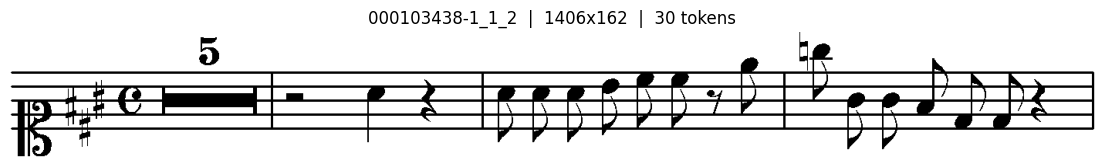

Family sequence:
clef.C accidental.sharp accidental.sharp accidental.sharp metersign.C digit.5 multirest barline rest.half note.quarter rest.quarter barline note.eighth note.eighth note.eighth note.eighth note.eighth note.eighth rest.eighth note.eighth barline accidental.natural note.eighth note.eighth note.eighth note.eighth note.eighth note.eighth rest.quarter barline

By family (count | positions in order of appearance):
  note.eighth             13 | S3 S3 S3 L4 S4 S4 S5 S6 L3 L3 S2 S1 S1
  barline                  4 | L1 L1 L1 L1
  accidental.sharp         3 | S2 L1 L3
  rest.quarter             2 | L3 L3
  clef.C                   1 | L1
  metersign.C              1 | L3
  digit.5                  1 | S5
  multirest                1 | L3
  rest.half                1 | L3
  note.quarter             1 | S3
  rest.eighth              1 | L3
  accidental.natural       1 | S6
--------------------------------------------------------------------------------


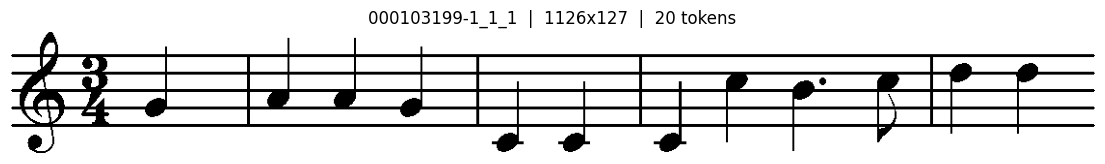

Family sequence:
clef.G digit.3 digit.4 note.quarter barline note.quarter note.quarter note.quarter barline note.quarter note.quarter barline note.quarter note.quarter note.quarter dot note.eighth barline note.quarter note.quarter

By family (count | positions in order of appearance):
  note.quarter            11 | L2 S2 S2 L2 L0 L0 L0 S3 L3 L4 L4
  barline                  4 | L1 L1 L1 L1
  clef.G                   1 | L2
  digit.3                  1 | L4
  digit.4                  1 | L2
  dot                      1 | S3
  note.eighth              1 | S3
--------------------------------------------------------------------------------


In [84]:
N_SHOW = 2

def split_token(tok):
    # Family = text before the first '-'; position may be negative (e.g. 'S-2')
    family, position = tok.split('-', 1)
    return family, position

# Not seeded on purpose: each run shows different samples
for sid in random.sample(list(index_df.id), k=N_SHOW):
    img = Image.open(paths[sid] / f'{sid}.png').convert('L')
    parsed = [split_token(t) for t in labels[sid]]

    plt.figure(figsize=(14, 3))
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title(f'{sid}  |  {img.width}x{img.height}  |  {len(parsed)} tokens')
    plt.show()

    # 1) Families in left-to-right order
    print('Family sequence:')
    print(' '.join(f for f, _ in parsed))

    # 2) Positions grouped by family
    by_family = defaultdict(list)
    for f, p in parsed:
        by_family[f].append(p)

    print('\nBy family (count | positions in order of appearance):')
    for f, positions in sorted(by_family.items(), key=lambda kv: -len(kv[1])):
        print(f'  {f:<22} {len(positions):>3} | {" ".join(positions)}')
    print('-' * 80)

### 12.1. Opcional (Reproductor mid)

In [85]:
#instalar pretty_midi
!pip install -q pretty_midi

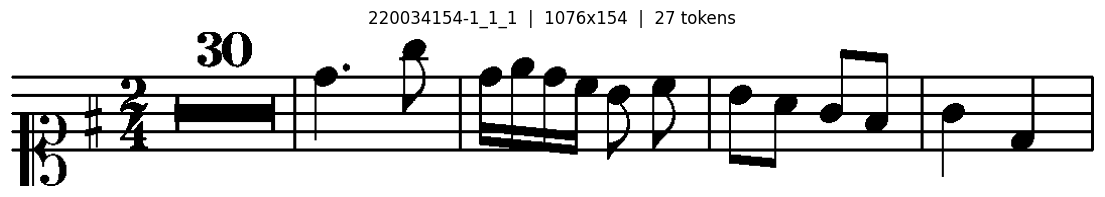

MIDI duration: 5.0 s


Family sequence:
clef.C accidental.sharp digit.2 digit.4 digit.3 digit.0 multirest barline note.quarter dot note.eighth barline note.beamedRight2 note.beamedBoth2 note.beamedBoth2 note.beamedLeft2 note.eighth note.eighth barline note.beamedRight1 note.beamedLeft1 note.beamedRight1 note.beamedLeft1 barline note.quarter note.quarter barline

By family (count | positions in order of appearance):
  barline                  5 | L1 L1 L1 L1 L1
  note.quarter             3 | L5 L3 S1
  note.eighth              3 | S6 L4 S4
  note.beamedBoth2         2 | S5 L5
  note.beamedRight1        2 | L4 L3
  note.beamedLeft1         2 | S3 S2
  clef.C                   1 | L1
  accidental.sharp         1 | S2
  digit.2                  1 | L4
  digit.4                  1 | L2
  digit.3                  1 | S5
  digit.0                  1 | S5
  multirest                1 | L3
  dot                      1 | S5
  note.beamedRight2        1 | L5
  note.beamedLeft2         1 | S4
---------------------------

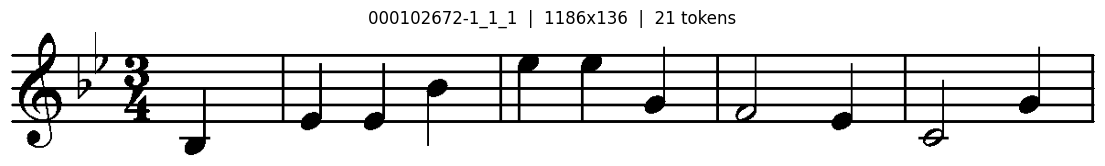

MIDI duration: 6.5 s


Family sequence:
clef.G accidental.flat accidental.flat digit.3 digit.4 note.quarter barline note.quarter note.quarter note.quarter barline note.quarter note.quarter note.quarter barline note.half note.quarter barline note.half note.quarter barline

By family (count | positions in order of appearance):
  note.quarter             9 | S-1 L1 L1 L3 S4 S4 L2 L1 L2
  barline                  5 | L1 L1 L1 L1 L1
  accidental.flat          2 | L3 S4
  note.half                2 | S1 L0
  clef.G                   1 | L2
  digit.3                  1 | L4
  digit.4                  1 | L2
--------------------------------------------------------------------------------


In [88]:
from IPython.display import Audio, display
import pretty_midi

N_SHOW = 2
SR = 22050  # sample rate for the synthesized audio

def split_token(tok):
    family, position = tok.split('-', 1)
    return family, position

# Not seeded on purpose: each run shows different samples
for sid in random.sample(list(index_df.id), k=N_SHOW):
    img = Image.open(paths[sid] / f'{sid}.png').convert('L')
    parsed = [split_token(t) for t in labels[sid]]

    plt.figure(figsize=(14, 3))
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title(f'{sid}  |  {img.width}x{img.height}  |  {len(parsed)} tokens')
    plt.show()

    # Mini MIDI player (sine-wave synthesis)
    pm = pretty_midi.PrettyMIDI(str(paths[sid] / f'{sid}.mid'))
    print(f'MIDI duration: {pm.get_end_time():.1f} s')
    display(Audio(pm.synthesize(fs=SR), rate=SR))

    print('Family sequence:')
    print(' '.join(f for f, _ in parsed))

    by_family = defaultdict(list)
    for f, p in parsed:
        by_family[f].append(p)

    print('\nBy family (count | positions in order of appearance):')
    for f, positions in sorted(by_family.items(), key=lambda kv: -len(kv[1])):
        print(f'  {f:<22} {len(positions):>3} | {" ".join(positions)}')
    print('-' * 80)